**Parte B — Con Python y scikit-learn:** una vez concluida la parte A, entrenar un `DecisionTreeClassifier(criterion="entropy")` con los mismos ejemplos y comparar su estructura y sus predicciones con el árbol dibujado a mano:

1. Leer el archivo `play_tennis.csv`, comprobar los nombres de las variables y construir `X` e `y`.
2. Codifique las variables categóricas utilizando `OneHotEncoder`.
3. Entrenar un `DecisionTreeClassifier` con `criterion="entropy"` y `random_state=42`, sin limitar inicialmente la profundidad.
4. Dibujar el árbol con `plot_tree` de scikit-learn, mostrando nombres de variables, entropía, cantidad de ejemplos y clases, determinar su profundidad, cantidad de nodos y hojas.
5. Compararlo con la **resolución en papel**: ¿coinciden las divisiones? ¿Puede cambiar la orientación Sí/No de una pregunta equivalente? ¿Cómo se representa una condición categórica binaria después de `OneHotEncoder`?

In [18]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

RANDOM_STATE = 42

df = pd.read_csv("./data/play_tennis.csv") #leemos dataset

print("Columnas:", df.columns.tolist())
print("Cantidad de ejemplos:", len(df))
display(df)

#construimos X e Y
X = df[["Pronostico", "Humedad", "Viento"]]
y = df["Juega"]

print("\nVariables predictoras:", X.columns.tolist())
print("Variable objetivo:", y.name)
print("Clases:", y.unique())


Columnas: ['ID', 'Pronostico', 'Humedad', 'Viento', 'Juega']
Cantidad de ejemplos: 8


,ID,Pronostico,Humedad,Viento,Juega
0,1,soleado,alta,no,no
1,2,nublado,alta,no,sí
2,3,lluvioso,normal,no,sí
3,4,lluvioso,normal,sí,no
4,5,soleado,alta,no,no
5,6,soleado,normal,no,sí
6,7,nublado,alta,sí,sí
7,8,lluvioso,alta,sí,no



Variables predictoras: ['Pronostico', 'Humedad', 'Viento']
Variable objetivo: Juega
Clases: <StringArray>
['no', 'sí']
Length: 2, dtype: str


In [19]:

#CODIFICAMOS VARIABLES
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_encoded = encoder.fit_transform(X)

feature_names = encoder.get_feature_names_out(X.columns)

X_encoded = pd.DataFrame(
    X_encoded,
    columns=feature_names,
    index=X.index
)

print("Nombres de las variables codificadas:")
print(feature_names)

display(X_encoded)

Nombres de las variables codificadas:
['Pronostico_lluvioso' 'Pronostico_nublado' 'Pronostico_soleado'
 'Humedad_alta' 'Humedad_normal' 'Viento_no' 'Viento_sí']


,Pronostico_lluvioso,Pronostico_nublado,Pronostico_soleado,Humedad_alta,Humedad_normal,Viento_no,Viento_sí
0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
1,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0,1.0,0.0
3,1.0,0.0,0.0,0.0,1.0,0.0,1.0
4,0.0,0.0,1.0,1.0,0.0,1.0,0.0
5,0.0,0.0,1.0,0.0,1.0,1.0,0.0
6,0.0,1.0,0.0,1.0,0.0,0.0,1.0
7,1.0,0.0,0.0,1.0,0.0,0.0,1.0


In [20]:
#ENTRENAMOS EL ÁRBOL
arbol = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

arbol.fit(X_encoded, y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

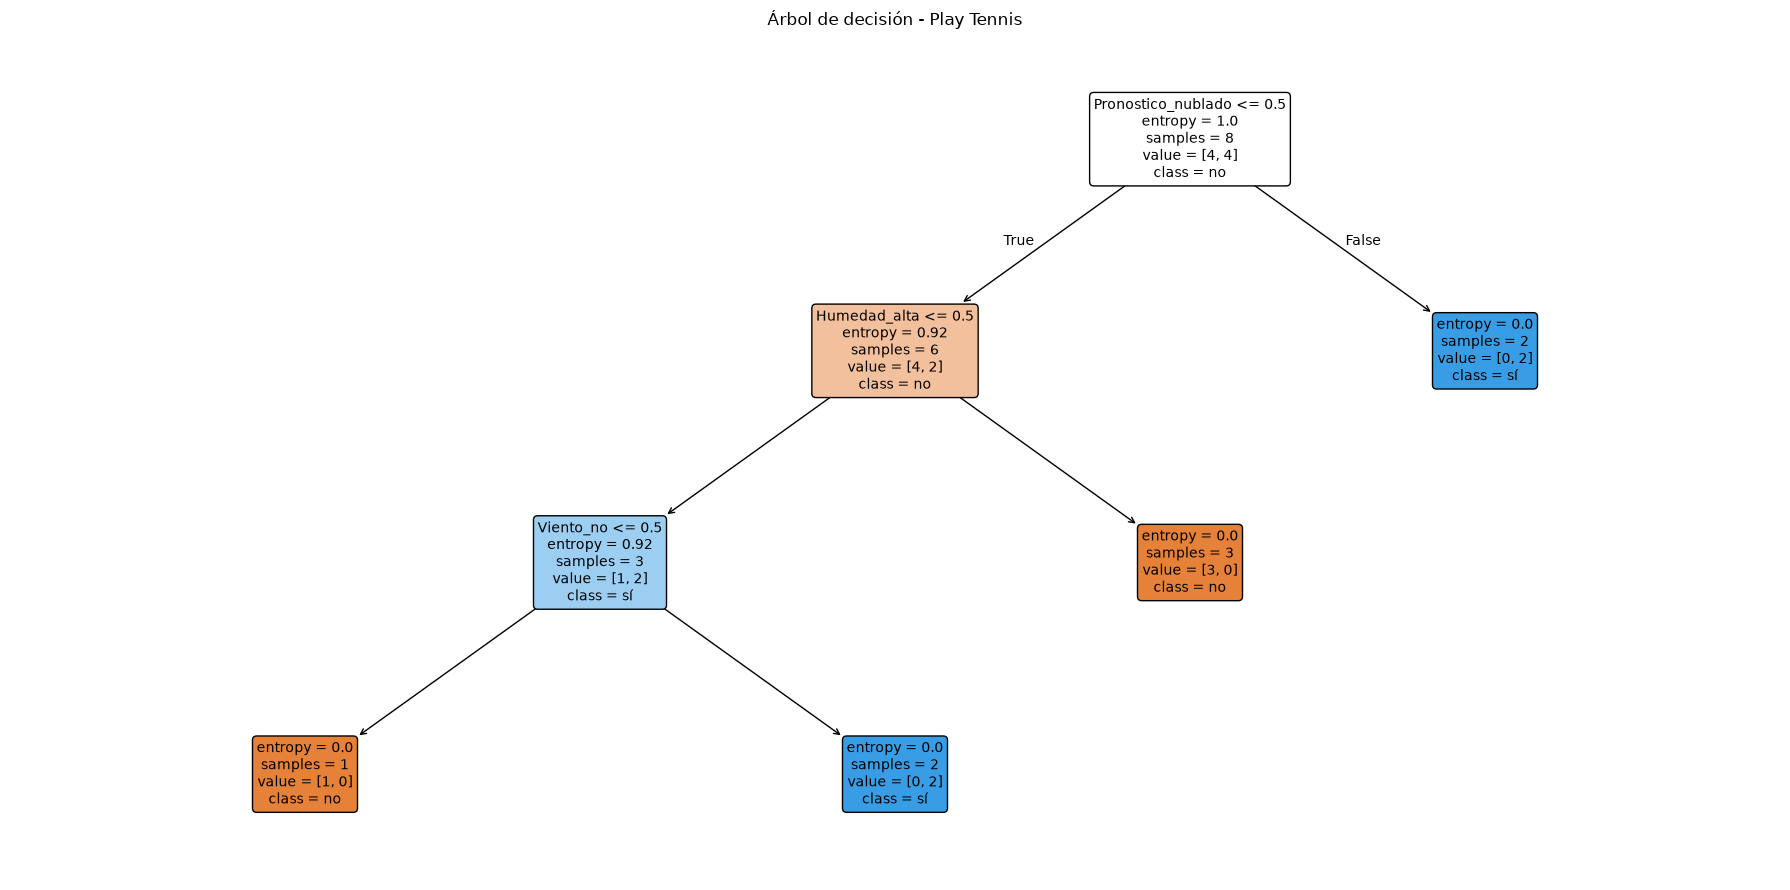

Profundidad: 3
Cantidad de nodos: 7
Cantidad de hojas: 4


In [21]:
#DIBUJAMOS ÁRBOL
plt.figure(figsize=(18, 9))

plot_tree(
    arbol,
    feature_names=list(feature_names),
    class_names=[str(clase) for clase in arbol.classes_],
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False,
    precision=2,
    fontsize=10
)

plt.title("Árbol de decisión - Play Tennis")
plt.tight_layout()
plt.show()

# Características estructurales
print("Profundidad:", arbol.get_depth())
print("Cantidad de nodos:", arbol.tree_.node_count)
print("Cantidad de hojas:", arbol.get_n_leaves())


Las divisiones coinciden, primero se divide teniendo en cuenta si el pronóstico anuncia "Nublado", luego teniendo en cuenta la Humedad y por último si hay o no viento.
Suponemos que sí, que da lo mismo intercambiar el orden de las respuestas puesto que es una clasificiación basada en evidencia, lo que no alteraría el resultado final.
Como se ve en la tabla, se crean columnas para cada condición, donde es 1 si se cumple la condición y 0 si no.

### 4. Ejercicio 2 — Iris: regiones de decisión, generalización y sobreajuste

En esta actividad se trabajará con el dataset **Iris** y con dos variables continuas:

- `petal length (cm)` (longitud del pétalo).
- `petal width (cm)` (ancho del pétalo).

El objetivo es relacionar **estructura del árbol**, **regiones del espacio de características** y **diferencias entre los resultados de entrenamiento y prueba**.

**Consignas:**

1. Cargar el dataset Iris, usando `load_iris()` seleccionar únicamente las dos características indicadas. Separar **70 % para entrenamiento y 30 % para prueba** (`random_state=42`, `stratify=y`).

2. Entrenar árboles con `criterion="entropy"` y `max_depth=2` y `max_depth=3`. Graficar cada árbol y sus regiones de decisión, marcando los datos de entrenamiento.

3. Entrenar otro árbol sin límite de profundidad (`max_depth=None`). Registrar para los tres modelos: profundidad obtenida, número de hojas, accuracy de entrenamiento y accuracy de prueba. Comparar: ¿más profundidad aumenta siempre el accuracy de entrenamiento? ¿Aumenta necesariamente el de prueba?

4. Explorar una restricción de **pre-poda**, por ejemplo `min_samples_leaf=4`. Comparar profundidad, número de hojas y resultados con los de un árbol sin ese límite.

5. Explicar qué representan en `plot_tree`: `entropy`, `samples`, `value` y `class`. Relacionar al menos un umbral con una frontera visible en el gráfico de regiones.

1. Cargar Iris y separar entrenamiento y prueba

In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

RANDOM_STATE = 42

iris = load_iris()

X = iris.data[:, [2, 3]]
y = iris.target

feature_names = [
    "petal length (cm)",
    "petal width (cm)"
]

class_names = iris.target_names

#70% entrenamiento, 30% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Total de ejemplos:", len(X))
print("Ejemplos de entrenamiento:", len(X_train))
print("Ejemplos de prueba:", len(X_test))

print("\nClases:", class_names)
print("\nDistribución de clases en entrenamiento:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nDistribución de clases en prueba:")
print(pd.Series(y_test).value_counts().sort_index())


Total de ejemplos: 150
Ejemplos de entrenamiento: 105
Ejemplos de prueba: 45

Clases: ['setosa' 'versicolor' 'virginica']

Distribución de clases en entrenamiento:
0    35
1    35
2    35
Name: count, dtype: int64

Distribución de clases en prueba:
0    15
1    15
2    15
Name: count, dtype: int64


2. Entrenar árboles de profundidad 2 y 3

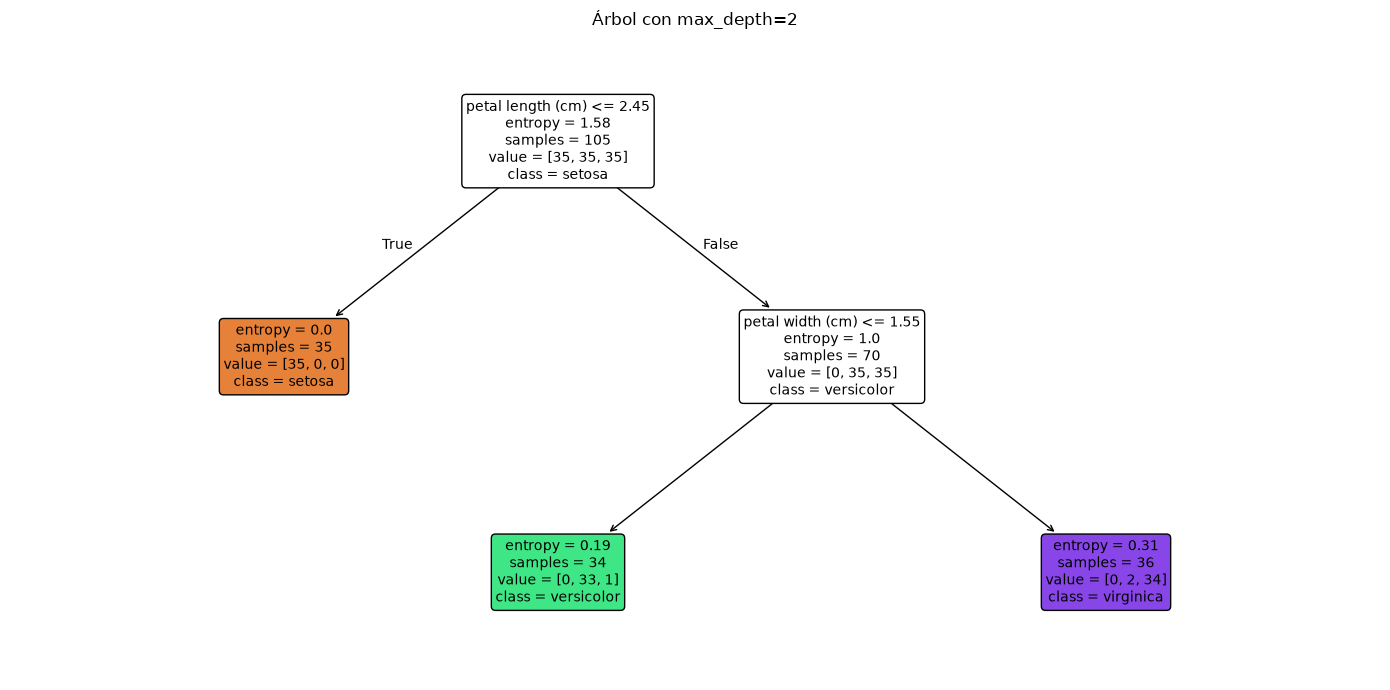

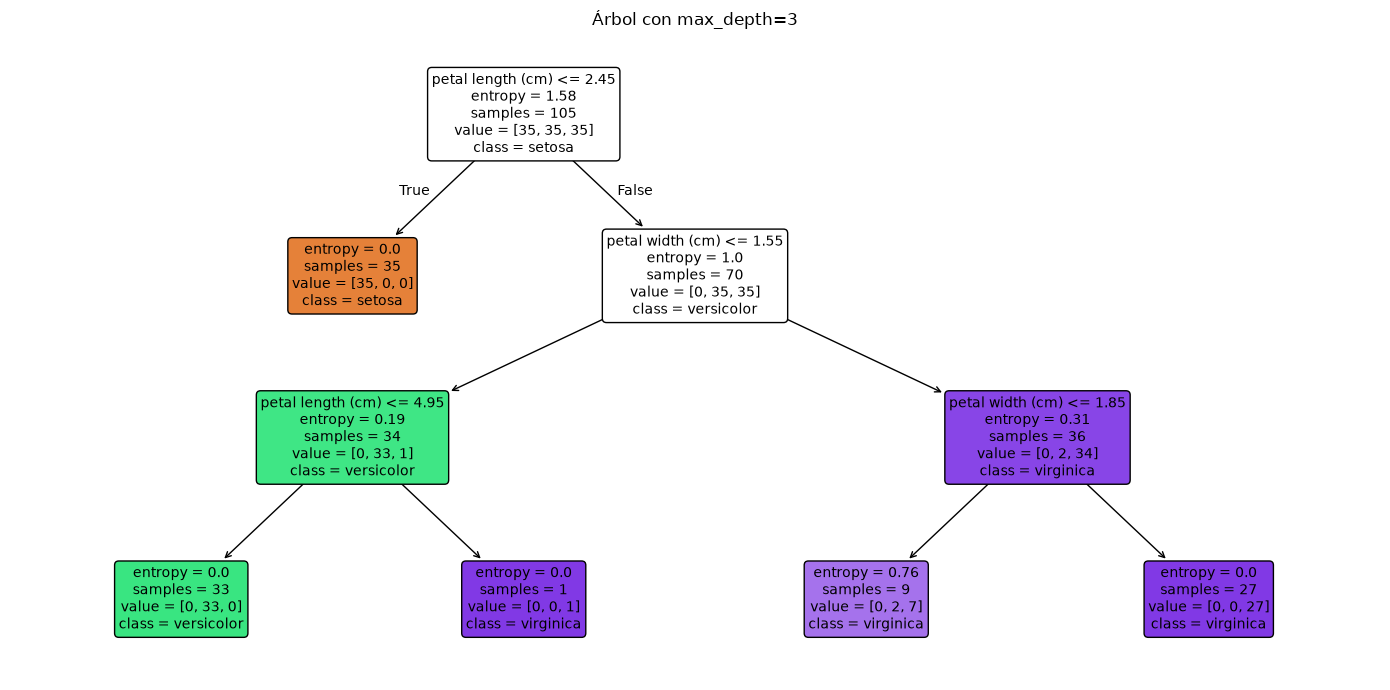

In [23]:

#ENTRENAMIENTO DE LOS ÁRBOLES
arbol_2 = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=2,
    random_state=RANDOM_STATE
)

arbol_3 = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=RANDOM_STATE
)

arbol_2.fit(X_train, y_train)
arbol_3.fit(X_train, y_train)


#GRAFICACIÓN DE LOS ÁRBOLES
for nombre, modelo in [
    ("Árbol con max_depth=2", arbol_2),
    ("Árbol con max_depth=3", arbol_3)
]:
    plt.figure(figsize=(14, 7))

    plot_tree(
        modelo,
        feature_names=feature_names,
        class_names=list(class_names),
        filled=True,
        rounded=True,
        impurity=True,
        proportion=False,
        precision=2,
        fontsize=10
    )

    plt.title(nombre)
    plt.tight_layout()
    plt.show()


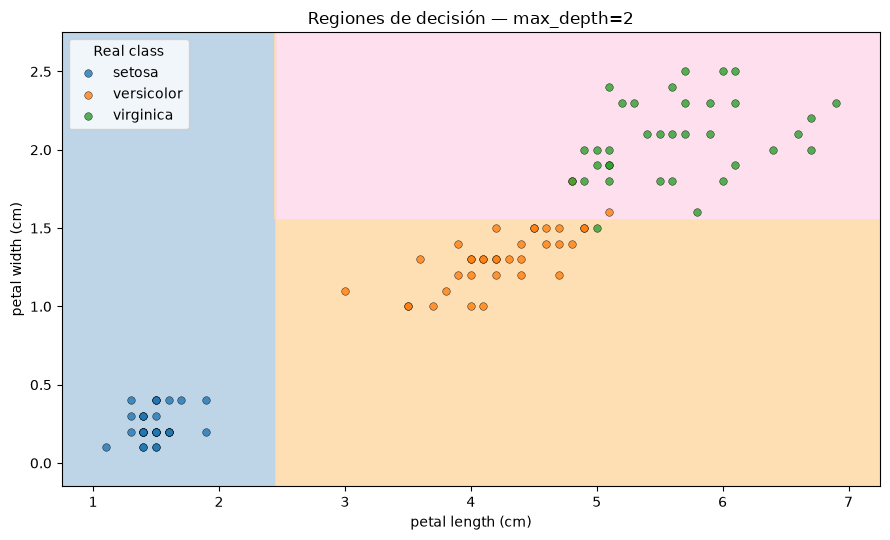

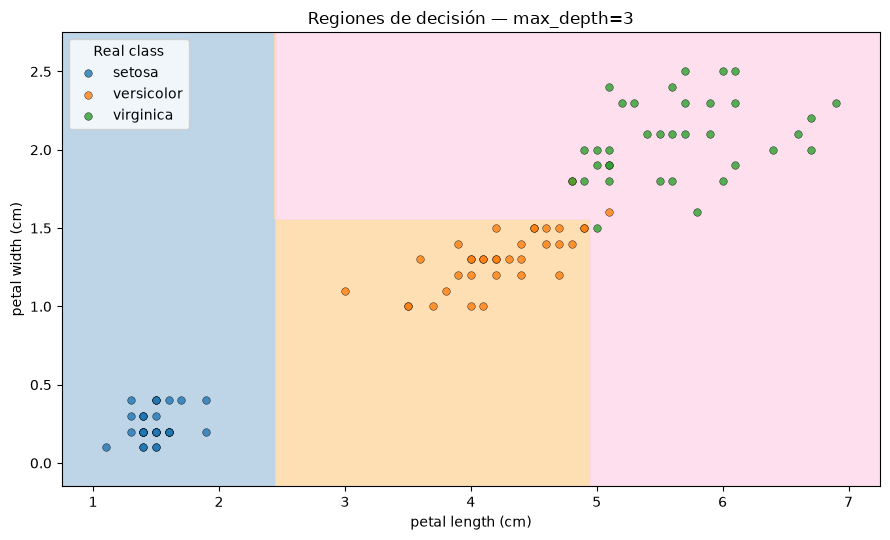

In [24]:

#GRAFICACIÓN DE REGIONES DE DECISIÓN

def plot_decision_regions(model, X, y, class_names, feature_names, title, resolution=240):
    """Plot a 2D decision map with observed samples overlaid."""
    x_min, x_max = X[:, 0].min() - 0.35, X[:, 0].max() + 0.35
    y_min, y_max = X[:, 1].min() - 0.25, X[:, 1].max() + 0.25

    x_grid = np.linspace(x_min, x_max, resolution)
    y_grid = np.linspace(y_min, y_max, resolution)
    xx, yy = np.meshgrid(x_grid, y_grid)
    grid_points = np.column_stack([xx.ravel(), yy.ravel()])
    predictions = model.predict(grid_points).reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.contourf(xx, yy, predictions, levels=[-0.5, 0.5, 1.5, 2.5], cmap="Pastel1", alpha=0.85)
    for class_id, class_name in enumerate(class_names):
        mask = y == class_id
        ax.scatter(X[mask, 0], X[mask, 1], s=30, label=class_name,
                   edgecolors="black", linewidths=0.35, alpha=0.8)
    ax.set(xlabel=feature_names[0], ylabel=feature_names[1], title=title)
    ax.legend(title="Real class")
    fig.tight_layout()
    plt.show()


#Se grafican las regiones para cada modelo
plot_decision_regions(
    arbol_2, X_train, y_train, class_names, feature_names,
    "Regiones de decisión — max_depth=2"
)

plot_decision_regions(
    arbol_3, X_train, y_train, class_names, feature_names,
    "Regiones de decisión — max_depth=3"
)


3. Árbol sin límite de profundidad y comparación de resultados

In [ ]:
#ENTRENAMIENTO DE ÁRBOL SIN LÍMITE

arbol_libre = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=None,
    random_state=RANDOM_STATE
)

arbol_libre.fit(X_train, y_train)

#JUNTAMOS LOS TRES ÁRBOLES
modelos = {
    "Profundidad 2": arbol_2,
    "Profundidad 3": arbol_3,
    "Sin límite": arbol_libre
}

#CALCULAMOS MÉTRICAS PARA CADA ÁRBOL
resultados = []

for nombre, modelo in modelos.items():
    resultados.append({
        "Modelo": nombre,
        "Profundidad obtenida": modelo.get_depth(),
        "Cantidad de hojas": modelo.get_n_leaves(),
        "Accuracy entrenamiento": accuracy_score(
            y_train, modelo.predict(X_train)
        ),
        "Accuracy prueba": accuracy_score(
            y_test, modelo.predict(X_test)
        )
    })

tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados.round(4))

,Modelo,Profundidad obtenida,Cantidad de hojas,Accuracy entrenamiento,Accuracy prueba
0,Profundidad 2,2,3,0.9714,0.8889
1,Profundidad 3,3,5,0.9810,0.9333
2,Sin límite,6,8,0.9905,0.9333


Para el dataset analizado, el valor de accuracy para entrenamiento aumenta siempre que aumenta la profundidad, lo que es esperable al permitir más divisiones.

No así con el accuracy para el set de prueba, se observa que para un árbol de profundidad 3 y uno de profundidad 6 se obtiene el mismo accuracy

La mayor profundidad permite ajustar mejor el entrenamiento, pero eso no implica que mejore la clasificación de los ejemplos nuevos. Las divisiones adicionales pueden capturar particularidades de los datos de entrenamiento que no se repiten en el conjunto de prueba.

4. Explorar la pre-poda con min_samples_leaf=4

In [11]:
#EXPLORACIÓN PRE-PODA
arbol_podado = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=None,
    min_samples_leaf=4,
    random_state=RANDOM_STATE
)

arbol_podado.fit(X_train, y_train)

# Comparar el árbol libre con el árbol podado
modelos_poda = {
    "Sin límite ni pre-poda": arbol_libre,
    "min_samples_leaf=4": arbol_podado
}

resultados_poda = []

for nombre, modelo in modelos_poda.items():
    resultados_poda.append({
        "Modelo": nombre,
        "Profundidad": modelo.get_depth(),
        "Hojas": modelo.get_n_leaves(),
        "Accuracy entrenamiento": accuracy_score(
            y_train, modelo.predict(X_train)
        ),
        "Accuracy prueba": accuracy_score(
            y_test, modelo.predict(X_test)
        )
    })

display(pd.DataFrame(resultados_poda).round(4))


,Modelo,Profundidad,Hojas,Accuracy entrenamiento,Accuracy prueba
0,Sin límite ni pre-poda,6,8,0.9905,0.9333
1,min_samples_leaf=4,4,6,0.9714,0.8889


En este caso la restricción no mejora el resultado de prueba en esta partición. Si bien la pre-poda puede reducir la complejidad y evitar el sobreajuste, no garantiza una mejora en todos los conjuntos de datos.

5. Interpretar plot_tree y relacionar un umbral con una frontera

entropy: representa la entropía de cada nodo, o sea, la impureza del mismo. 

samples: cantidad de ejemplos que llegaron a cada nodo.

value: explica cuántos ejemplos de cada clase hay en el nodo.

class: representa la clase que el árbol predice en el nodo.


En el árbol de profundidad 2 se divide teniendo en cuenta el valor 2,45cm para el atributo petal_length; a la izquierda de esta frontera se predice la clase Setosa, mientras que a la dereca se siguen evaluando otras condiciones. La siguiente división se hace teniendo en cuenta el petal_width y el valor 1,55 para dicho atributo, separando ahora de forma horizontal para terminar de clasificar entre Versicolor y Virginica